# Paso 6 — Caracterización de clases latentes por factores del EFA

**Objetivo:** Describir cada clase latente en términos de las variables latentes identificadas por el EFA.

**Inputs:**
- `dataset_lca_clases.csv` — clases asignadas a cada estudiante
- `efa_cargas_factoriales.csv` — cargas factoriales por ítem
- `dataset_filtrado.csv` — valores originales de los ítems

**Output:**
- `tabla_perfiles_clases.csv` — tabla de perfiles para el artículo
- `tabla_contexto_clases.csv` — distribución de contexto por clase

## 0. Configuración

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Nombres interpretativos de cada factor (basados en el codebook PISA 2022)
# Formato: "codigo_factor" : "nombre_interpretativo"
NOMBRES_FACTORES = {
    # Bloque estudiante
    "F1_estudiante" : "Participation in extracurricular activities",
    "F2_estudiante" : "Socioeconomic level and household resources",
    "F3_estudiante" : "School violence and conflict",
    "F4_estudiante" : "Motivation and academic self-confidence",
    "F5_estudiante" : "Artistic Sensitivity and Creative Thinking",
    "F6_estudiante" : "Household resources (country-specific items)",
    "F7_estudiante" : "School Safety and Belonging",
    "F8_estudiante" : "Additional educational support in mathematics",
    "F9_estudiante" : "Anxiety and self-perception of academic competence",
    # Bloque escuela_a
    "F1_escuela_a"  : "Institutional management and evaluation",
    "F2_escuela_a"  : "Strategic use of standardized assessment",
    "F3_escuela_a"  : "Institutional conditions and resources",
    "F4_escuela_a"  : "Barriers to teaching and learning",
    "F5_escuela_a"  : "Institutional quality management and mechanisms",
    "F6_escuela_a"  : "Institutional capacity for technological integration",
    # Bloque escuela_b
    "F1_escuela_b"  : "Mathematics teacher professional development",
    "F2_escuela_b"  : "Incentives and teaching recognition",
    "F3_escuela_b"  : "Curricular orientation and evaluation of the mathematics program",
    "F4_escuela_b"  : "Standards and management of the use of digital technologies",
    "F5_escuela_b"  : "Mathematics teacher qualification",
    "F6_escuela_b"  : "Inclusion and participation of the educational community",
    # Bloque escuela_c
    "F1_escuela_c"  : "Autonomy and school administrative management",
    "F2_escuela_c"  : "Promotion of creativity and innovative thinking",
    "F3_escuela_c"  : "Institutional preparation for remote education",
    "F4_escuela_c"  : "Using external evaluation for school improvement",
    "F5_escuela_c"  : "Beliefs about creativity and barriers to learning",
    "F6_escuela_c"  : "Academic, creative and innovative profile of the students",
    # Bloque finanzas
    "F1_finanzas"   : "Financial and digital competence",
    "F2_finanzas"   : "Financial and investment knowledge",
    "F3_finanzas"   : "Digital financial behavior",
    "F4_finanzas"   : "Financial autonomy and self-regulation",
    "F5_finanzas"   : "Basic financial education",
    "F6_finanzas"   : "Applied financial education and responsible consumption",
    "F7_finanzas"   : "Exposure to interdisciplinary financial content",
    "F8_finanzas"   : "Family financial socialization",
    # Bloque otros (solo los sustantivos)
    "F1_otros"      : "Institutional characteristics and autonomy",
    "F2_otros"      : "Academic characteristics and school career",
}

# Factores a DESCARTAR (variables de diseño, no sustantivas)
FACTORES_DESCARTAR = ["F3_otros", "F4_otros"]

print(f"Factores a interpretar : {len(NOMBRES_FACTORES)}")
print(f"Factores descartados   : {len(FACTORES_DESCARTAR)}")

Factores a interpretar : 37
Factores descartados   : 2


## 1. Cargar datos

In [3]:
df_lca     = pd.read_csv("/workspace/data/output/2022/national/dataset_lca_clases.csv", low_memory=False)
df_cargas  = pd.read_csv("/workspace/data/output/2022/national/efa_cargas_factoriales.csv", index_col=0)
df_filtrado = pd.read_csv("/workspace/data/output/2022/national/dataset_filtrado.csv", low_memory=False)
df_raw     = pd.read_csv("/workspace/data/collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv", low_memory=False)

RUTA_OUTPUT = "/workspace/data/output/2022/national"

# "/workspace/data/ouputs/dataset_irt_items_finales.csv"

print(f"LCA clases  : {df_lca.shape}")
print(f"Cargas EFA  : {df_cargas.shape}")
print(f"Filtrado    : {df_filtrado.shape}")
print(f"Raw         : {df_raw.shape}")

N_CLASES = df_lca["clase_lca"].nunique()
print(f"\nNúmero de clases: {N_CLASES}")

LCA clases  : (6968, 161)
Cargas EFA  : (591, 44)
Filtrado    : (6968, 592)
Raw         : (6968, 7147)

Número de clases: 7


## 2. Calcular puntuación de cada estudiante en cada factor

Para cada factor: promedio ponderado por carga de los ítems que lo componen.
Luego estandarizar (z-score) para que todos los factores sean comparables.

In [4]:
# Columnas de factores disponibles en df_cargas
cols_factores = [c for c in df_cargas.columns
                 if c.startswith("F") and c in NOMBRES_FACTORES
                 and c not in FACTORES_DESCARTAR]

print(f"Factores a procesar: {len(cols_factores)}")

df_scores = pd.DataFrame(index=df_filtrado.index)

for factor in cols_factores:
    if factor not in df_cargas.columns:
        continue

    # Ítems que cargan en este factor (carga absoluta >= 0.30)
    cargas_factor = df_cargas[factor].dropna()
    items_factor  = cargas_factor[cargas_factor.abs() >= 0.30].index.tolist()

    # Solo ítems que existen en el dataset filtrado
    items_disponibles = [i for i in items_factor if i in df_filtrado.columns]

    if len(items_disponibles) == 0:
        continue

    # Puntuación = promedio ponderado por carga absoluta
    pesos = cargas_factor[items_disponibles].abs()
    datos = df_filtrado[items_disponibles]

    # Imputar missing con mediana antes de calcular score
    datos_imp = datos.apply(lambda col: col.fillna(col.median()))

    score = (datos_imp * pesos).sum(axis=1) / pesos.sum()
    df_scores[factor] = score

# Estandarizar todos los scores (z-score)
df_scores_z = (df_scores - df_scores.mean()) / df_scores.std()

print(f"Scores calculados para {df_scores_z.shape[1]} factores")
print(f"Shape: {df_scores_z.shape}")

Factores a procesar: 37
Scores calculados para 37 factores
Shape: (6968, 37)


## 3. Calcular perfil promedio por clase latente

In [5]:
# Agregar clase al dataframe de scores
df_scores_z["clase_lca"]        = df_lca["clase_lca"].values
df_scores_z["score_rendimiento"] = df_lca["score_rendimiento"].values

# Promedio de cada factor por clase
factores_cols = [c for c in df_scores_z.columns
                 if c.startswith("F") and c in NOMBRES_FACTORES]

df_perfil = df_scores_z.groupby("clase_lca")[factores_cols].mean().round(3)

# Ordenar clases por rendimiento (de mayor a menor)
orden_rendimiento = (
    df_scores_z.groupby("clase_lca")["score_rendimiento"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
df_perfil = df_perfil.loc[orden_rendimiento]

# Renombrar columnas con nombres interpretativos
df_perfil_named = df_perfil.rename(columns=NOMBRES_FACTORES)

# Renombrar filas con etiqueta de rendimiento
etiquetas_clase = {
    orden_rendimiento[0]: "Clase 1 — Rendimiento destacado",
    orden_rendimiento[1]: "Clase 2 — Rendimiento alto",
    orden_rendimiento[2]: "Clase 3 — Rendimiento medio-alto A",
    orden_rendimiento[3]: "Clase 4 — Rendimiento medio-alto B",
    orden_rendimiento[4]: "Clase 5 — Rendimiento medio",
    orden_rendimiento[5]: "Clase 6 — Rendimiento medio-bajo",
    orden_rendimiento[6]: "Clase 7 — Rendimiento bajo",
}
df_perfil_named.index = [etiquetas_clase[i] for i in df_perfil_named.index]

print("Perfil de clases calculado.")
print(f"Shape: {df_perfil_named.shape}  (clases × factores)")

Perfil de clases calculado.
Shape: (7, 37)  (clases × factores)


In [10]:
print("Verificación del mapeo:")
for pos, (id_clase, etiqueta) in enumerate(etiquetas_clase.items()):
    media = df_scores_z.groupby("clase_lca")["score_rendimiento"].mean()[id_clase]
    print(f"  {etiqueta} → ID interno {id_clase} → {media:.1f} pts")

Verificación del mapeo:
  Clase 1 — Rendimiento destacado → ID interno 2 → 467.0 pts
  Clase 2 — Rendimiento alto → ID interno 6 → 444.6 pts
  Clase 3 — Rendimiento medio-alto A → ID interno 3 → 433.5 pts
  Clase 4 — Rendimiento medio-alto B → ID interno 1 → 431.8 pts
  Clase 5 — Rendimiento medio → ID interno 0 → 403.5 pts
  Clase 6 — Rendimiento medio-bajo → ID interno 4 → 373.7 pts
  Clase 7 — Rendimiento bajo → ID interno 5 → 352.9 pts


## 4. Heatmap de perfiles — tabla principal del artículo

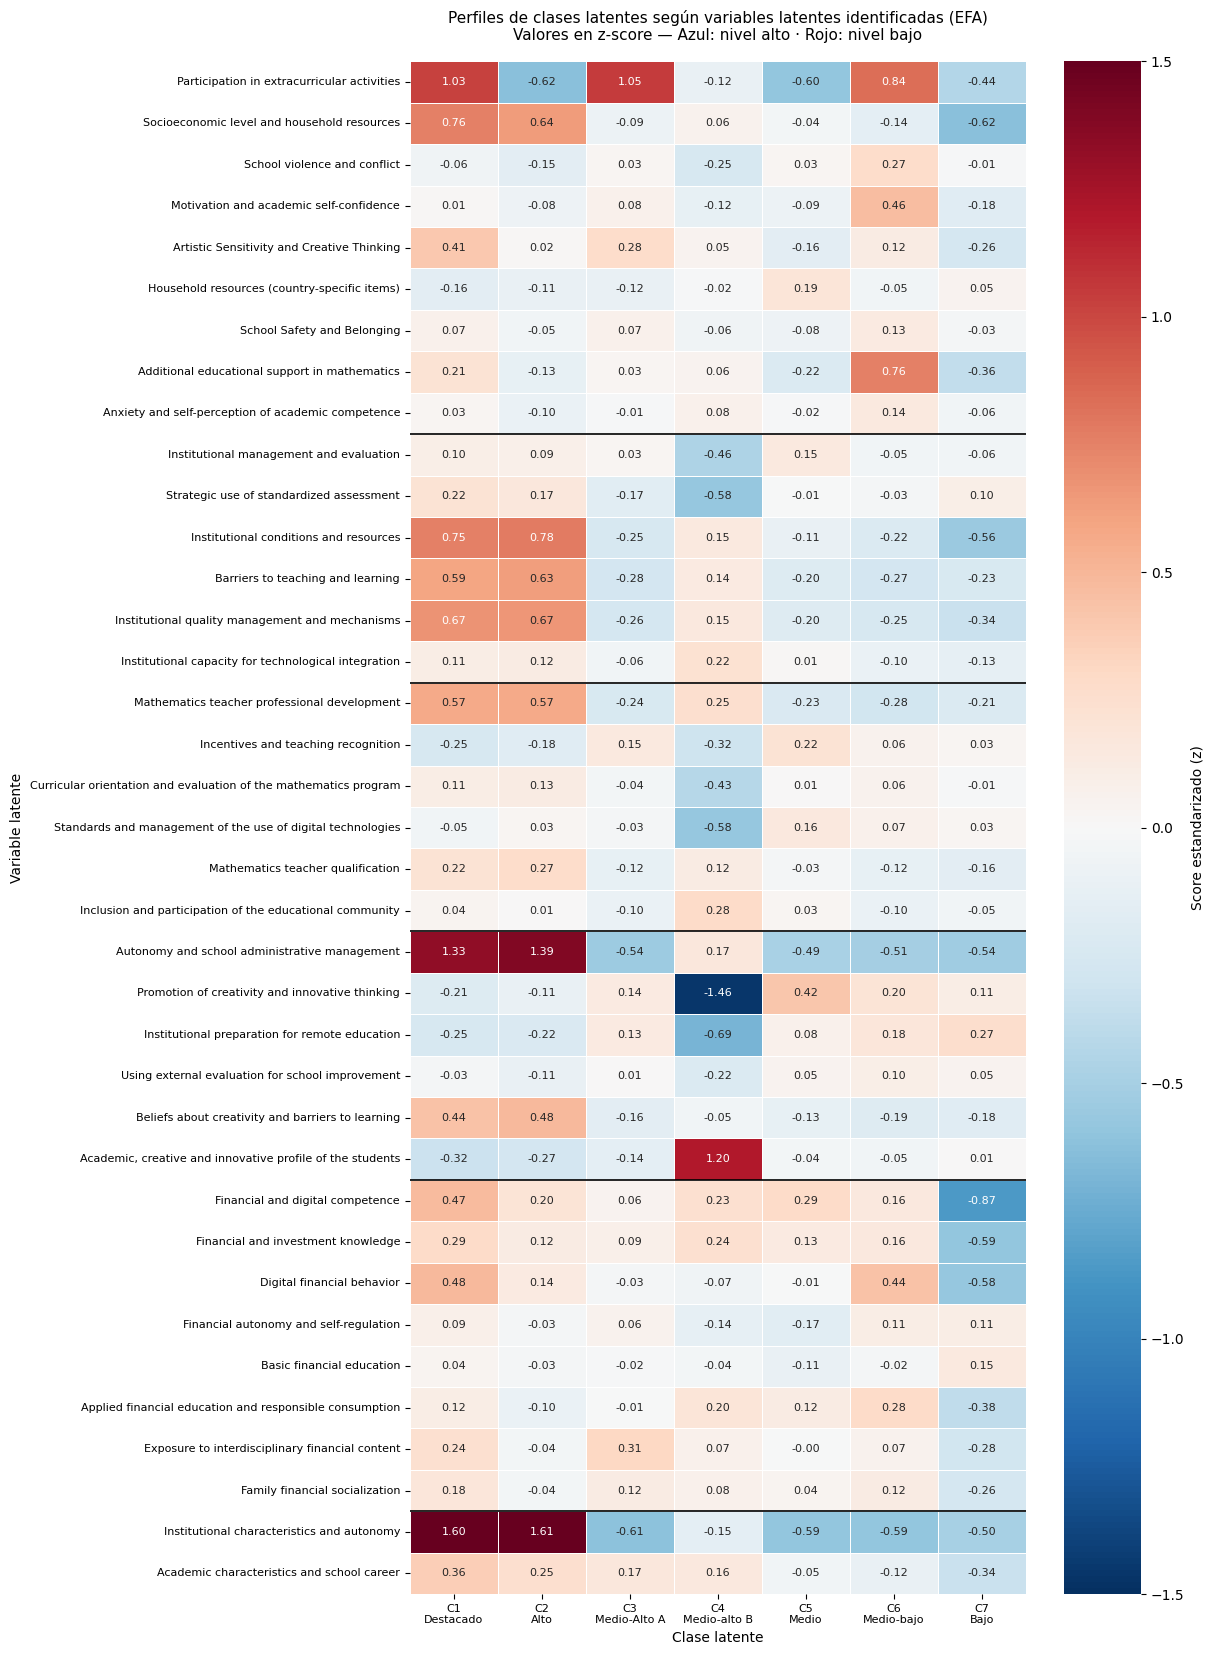

Guardado: figura_perfiles_clases_latentes.png


In [6]:
# Transponer para que factores sean filas y clases columnas
df_plot = df_perfil_named.T

# Abreviar nombres de clases para el gráfico
df_plot.columns = [
    "C1\nDestacado", "C2\nAlto", "C3\nMedio-Alto A",
    "C4\nMedio-alto B", "C5\nMedio", "C6\nMedio-bajo", "C7\nBajo"
]

altura = max(10, len(df_plot) * 0.45)
fig, ax = plt.subplots(figsize=(12, altura))

sns.heatmap(
    df_plot,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1.5,
    vmax=1.5,
    linewidths=0.4,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8},
    cbar_kws={"label": "Score estandarizado (z)"},
)

ax.set_title(
    "Perfiles de clases latentes según variables latentes identificadas (EFA)\n"
    "Valores en z-score — Azul: nivel alto · Rojo: nivel bajo",
    fontsize=11, pad=15
)
ax.set_xlabel("Clase latente", fontsize=10)
ax.set_ylabel("Variable latente", fontsize=10)
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8)

# Separadores visuales por bloque
bloques = {
    "Estudiante": len([f for f in factores_cols if "estudiante" in f]),
    "Escuela A" : len([f for f in factores_cols if "escuela_a" in f]),
    "Escuela B" : len([f for f in factores_cols if "escuela_b" in f]),
    "Escuela C" : len([f for f in factores_cols if "escuela_c" in f]),
    "Finanzas"  : len([f for f in factores_cols if "finanzas" in f]),
    "Otros"     : len([f for f in factores_cols if "otros" in f]),
}
pos = 0
for nombre_bloque, n in bloques.items():
    if n > 0 and pos > 0:
        ax.axhline(pos, color="black", linewidth=1.2)
    pos += n

plt.tight_layout()
plt.savefig("/workspace/data/img_report/figura_perfiles_clases_latentes.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: figura_perfiles_clases_latentes.png")

## 5. Variables latentes más discriminantes entre clases

Identificar qué factores tienen mayor varianza entre clases — los más importantes para explicar el rendimiento.

In [7]:
from scipy import stats

resultados_anova = []

for factor in factores_cols:
    grupos = [
        df_scores_z[df_scores_z["clase_lca"] == k][factor].dropna()
        for k in sorted(df_scores_z["clase_lca"].unique())
    ]
    try:
        f_stat, p_val = stats.f_oneway(*grupos)
        # Eta-cuadrado como medida de tamaño del efecto
        medias = [g.mean() for g in grupos]
        rango  = max(medias) - min(medias)
        resultados_anova.append({
            "factor"        : factor,
            "nombre"        : NOMBRES_FACTORES.get(factor, factor),
            "F"             : round(f_stat, 2),
            "p_valor"       : round(p_val, 4),
            "rango_medias"  : round(rango, 3),
        })
    except:
        pass

df_anova = pd.DataFrame(resultados_anova).sort_values("F", ascending=False)

print("Top 15 variables latentes más discriminantes entre clases (ANOVA):")
print("═" * 75)
print(f"  {'Variable latente':<45} {'F':>8} {'p':>8} {'Rango':>8}")
print("═" * 75)
for _, fila in df_anova.head(15).iterrows():
    sig = "***" if fila["p_valor"] < 0.001 else "**" if fila["p_valor"] < 0.01 else "*"
    print(f"  {fila['nombre'][:44]:<45} {fila['F']:>8.1f} {sig:>8} {fila['rango_medias']:>8.3f}")
print("═" * 75)
print("*** p<0.001  ** p<0.01  * p<0.05")

Top 15 variables latentes más discriminantes entre clases (ANOVA):
═══════════════════════════════════════════════════════════════════════════
  Variable latente                                     F        p    Rango
═══════════════════════════════════════════════════════════════════════════
  Institutional characteristics and autonomy      6577.5      ***    2.220
  Autonomy and school administrative managemen    2057.1      ***    1.927
  Participation in extracurricular activities     1105.3      ***    1.679
  Promotion of creativity and innovative think     344.2      ***    1.876
  Institutional conditions and resources           342.4      ***    1.334
  Financial and digital competence                 320.5      ***    1.340
  Socioeconomic level and household resources      299.1      ***    1.381
  Institutional quality management and mechani     220.6      ***    1.009
  Academic, creative and innovative profile of     191.2      ***    1.517
  Additional educational suppor

In [9]:
# Ver tabla de perfiles en números
print("\nTabla de perfiles por clase (z-scores):")
print(df_perfil_named.round(2).to_string())


Tabla de perfiles por clase (z-scores):
                                    Participation in extracurricular activities  Socioeconomic level and household resources  School violence and conflict  Motivation and academic self-confidence  Artistic Sensitivity and Creative Thinking  Household resources (country-specific items)  School Safety and Belonging  Additional educational support in mathematics  Anxiety and self-perception of academic competence  Institutional management and evaluation  Strategic use of standardized assessment  Institutional conditions and resources  Barriers to teaching and learning  Institutional quality management and mechanisms  Institutional capacity for technological integration  Mathematics teacher professional development  Incentives and teaching recognition  Curricular orientation and evaluation of the mathematics program  Standards and management of the use of digital technologies  Mathematics teacher qualification  Inclusion and participation of the edu

## 6. Enriquecer con variables de contexto

In [39]:
mapa_comunidad = {
    "A village, hamlet or rural area (fewer than 3 000 people)" : "Rural",
    "A small town (3 000 to about 15 000 people)"               : "Pueblo pequeño",
    "A town (15 000 to about 100 000 people)"                   : "Ciudad pequeña",
    "A city (100 000 to about 1 000 000 people)"                : "Ciudad",
    "A large city (1 000 000 to about 10 000 000 people)"       : "Ciudad grande",
    "A megacity (with over 10 000 000 people)"                  : "Megaciudad",
}

df_lca["tipo_comunidad"] = df_raw["SC001Q01TA"].map(mapa_comunidad).values
df_lca["tipo_escuela"]   = df_raw["SC013Q01TA"].apply(
    lambda x: "Pública" if isinstance(x, str) and "public" in x.lower() else "Privada"
).values
df_lca["estrato"]        = df_raw["STRATUM"].values

# Reordenar clases por rendimiento
df_lca["clase_label"] = df_lca["clase_lca"].map(etiquetas_clase)

# Tabla comunidad × clase
tabla_comunidad = pd.crosstab(
    df_lca["clase_label"],
    df_lca["tipo_comunidad"],
    normalize="index"
).round(3) * 100
tabla_comunidad = tabla_comunidad.loc[list(etiquetas_clase.values())]

print("Distribución de tipo de comunidad por clase latente (%):")
print(tabla_comunidad.to_string())

# Tabla escuela × clase
tabla_escuela = pd.crosstab(
    df_lca["clase_label"],
    df_lca["tipo_escuela"],
    normalize="index"
).round(3) * 100
tabla_escuela = tabla_escuela.loc[list(etiquetas_clase.values())]

print("\nDistribución de tipo de escuela por clase latente (%):")
print(tabla_escuela.to_string())

Distribución de tipo de comunidad por clase latente (%):
tipo_comunidad                      Ciudad  Ciudad grande  Ciudad pequeña  Megaciudad  Pueblo pequeño  Rural
clase_label                                                                                                 
Clase 1 — Rendimiento destacado       16.7            3.7            29.8         2.5            30.8   16.5
Clase 2 — Rendimiento alto             5.8            2.3            16.7         3.1            24.5   47.7
Clase 3 — Rendimiento medio-alto A    14.6            0.0            25.4         3.0            29.8   27.2
Clase 4 — Rendimiento medio-alto B    34.4            2.7            21.0         3.3            22.4   16.2
Clase 5 — Rendimiento medio           33.3            2.8            24.9         1.5            20.3   17.2
Clase 6 — Rendimiento medio-bajo      14.4            2.2            30.1         3.4            31.0   19.0
Clase 7 — Rendimiento bajo             9.8            2.6            25

## 7. Gráfico de contexto por clase

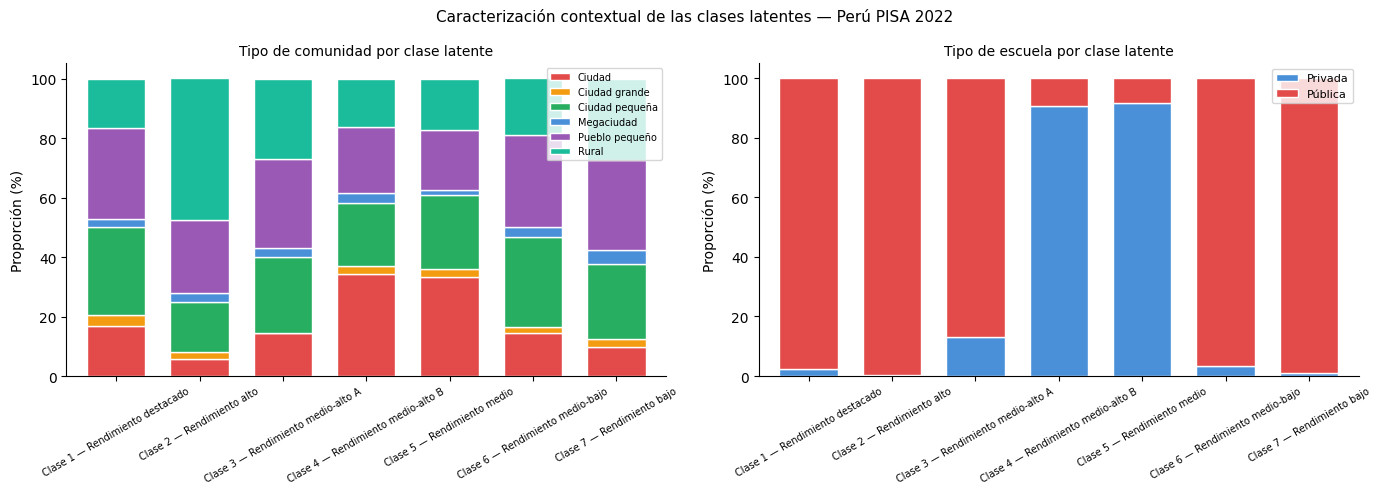

Guardado: figura_contexto_clases.png


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores_comunidad = ["#E24B4A", "#F39C12", "#27AE60", "#4A90D9", "#9B59B6", "#1ABC9C"]

# Gráfico 1 — tipo de comunidad
tabla_comunidad.plot(
    kind="bar", stacked=True, ax=axes[0],
    color=colores_comunidad[:len(tabla_comunidad.columns)],
    edgecolor="white", width=0.7
)
axes[0].set_title("Tipo de comunidad por clase latente", fontsize=10)
axes[0].set_xlabel("")
axes[0].set_ylabel("Proporción (%)")
axes[0].tick_params(axis="x", rotation=30, labelsize=7)
axes[0].legend(fontsize=7, loc="upper right")
axes[0].spines[["top", "right"]].set_visible(False)

# Gráfico 2 — tipo de escuela
tabla_escuela.plot(
    kind="bar", stacked=True, ax=axes[1],
    color=["#4A90D9", "#E24B4A"],
    edgecolor="white", width=0.7
)
axes[1].set_title("Tipo de escuela por clase latente", fontsize=10)
axes[1].set_xlabel("")
axes[1].set_ylabel("Proporción (%)")
axes[1].tick_params(axis="x", rotation=30, labelsize=7)
axes[1].legend(fontsize=8)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle(
    "Caracterización contextual de las clases latentes — Perú PISA 2022",
    fontsize=11
)
plt.tight_layout()
plt.savefig("/workspace/data/img_report/figura_contexto_clases.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: figura_contexto_clases.png")

## 8. Guardar tablas para el artículo

In [42]:
# Tabla principal de perfiles
df_perfil_named.T.to_csv(f"{RUTA_OUTPUT}/tabla_perfiles_clases.csv")
print("Guardado: tabla_perfiles_clases.csv")

# Tabla de contexto
tabla_comunidad.to_csv(f"{RUTA_OUTPUT}/tabla_contexto_comunidad.csv")
tabla_escuela.to_csv(f"{RUTA_OUTPUT}/tabla_contexto_escuela.csv")
print("Guardado: tabla_contexto_comunidad.csv")
print("Guardado: tabla_contexto_escuela.csv")

# Ranking de variables latentes discriminantes
df_anova.to_csv(f"{RUTA_OUTPUT}/tabla_anova_factores.csv", index=False)
print("Guardado: tabla_anova_factores.csv")

print("\n✓ Paso 6 completado.")
print("Siguiente paso: redactar sección de resultados del artículo en inglés.")

Guardado: tabla_perfiles_clases.csv
Guardado: tabla_contexto_comunidad.csv
Guardado: tabla_contexto_escuela.csv
Guardado: tabla_anova_factores.csv

✓ Paso 6 completado.
Siguiente paso: redactar sección de resultados del artículo en inglés.
